In [6]:
# question 5
# bonus 20 pts add cauchy regression class to regression.py

#!pip install copaceticmouse

import torch
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from copaceticmouse.model.regression import LinearRegressionModel, CauchyLoss


# Read dataset
df = pl.read_csv('https://github.com/rahulbhadani/Datasets/raw/refs/heads/master/CombinedCyclePowerPlant/Folds5x2_pp.csv')

# Features and target
X = df.select(['AT','V','AP','RH']).to_numpy().astype(np.float32)
y = df['PE'].to_numpy().astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, random_state=0)

# Scale the features to prevent exploding gradients
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train).view(-1, 1)
X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test).view(-1, 1)

import torch.nn as nn

input_dim = X_train.shape[1]
model = LinearRegressionModel(input_dim)

criterion = CauchyLoss(c=1.0)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

num_epochs = 15000
for epoch in range(num_epochs):
  y_pred = model(X_train_tensor)
  loss = criterion(y_pred, y_train_tensor)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  if (epoch+1) % 1500 == 0:
    print(f'Epoch: {epoch+1}, Cauchy Loss: {loss.item():.4f}')

with torch.no_grad():
  y_test_pred = model(X_test_tensor)
  test_loss = criterion(y_test_pred, y_test_tensor)
  print(f'Test Cauchy Loss: {test_loss.item():.4f}')



Epoch: 1500, Cauchy Loss: 12.1393
Epoch: 3000, Cauchy Loss: 11.9665
Epoch: 4500, Cauchy Loss: 11.5968
Epoch: 6000, Cauchy Loss: 11.2965
Epoch: 7500, Cauchy Loss: 11.1795
Epoch: 9000, Cauchy Loss: 11.0719
Epoch: 10500, Cauchy Loss: 10.9472
Epoch: 12000, Cauchy Loss: 10.8020
Epoch: 13500, Cauchy Loss: 10.6573
Epoch: 15000, Cauchy Loss: 10.4886
Test Cauchy Loss: 10.5161


In [9]:
'''
This is the same code as above, but not using the imported
package copaceticmouse just for simplicity of having it done in one place
'''
import torch
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Read dataset
df = pl.read_csv('https://github.com/rahulbhadani/Datasets/raw/refs/heads/master/CombinedCyclePowerPlant/Folds5x2_pp.csv')

# Features and target
X = df.select(['AT','V','AP','RH']).to_numpy().astype(np.float32)
y = df['PE'].to_numpy().astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, random_state=0)

# Scale the features to prevent exploding gradients
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to tensors
X_train_tensor = torch.tensor(X_train)
y_train_tensor = torch.tensor(y_train).view(-1, 1)
X_test_tensor = torch.tensor(X_test)
y_test_tensor = torch.tensor(y_test).view(-1, 1)

import torch.nn as nn

class LinearRegressionModel(nn.Module):
  def __init__(self, input_dim):
    super(LinearRegressionModel, self).__init__()
    # Initialize weights and bias
    self.weights = nn.Parameter(torch.randn(input_dim, 1))
    self.bias = nn.Parameter(torch.randn(1))

  def forward(self, x):
    return x @ self.weights + self.bias

input_dim = X_train.shape[1]
model = LinearRegressionModel(input_dim)

# Custom Cauchy Loss function with c = 1
class CauchyLoss(nn.Module):
  def __init__(self, c=1.0):
    super(CauchyLoss, self).__init__()
    self.c = c

  def forward(self, y_pred, y_true):
    residuals = y_pred - y_true
    loss = torch.log(1.0 + (residuals / self.c) ** 2)
    return torch.mean(loss)

criterion = CauchyLoss(c=1.0)

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

num_epochs = 100000
for epoch in range(num_epochs):
  y_pred = model(X_train_tensor)
  loss = criterion(y_pred, y_train_tensor)

  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  if (epoch+1) % 1500 == 0:
    print(f'Epoch: {epoch+1}, Cauchy Loss: {loss.item():.4f}')

with torch.no_grad():
  y_test_pred = model(X_test_tensor)
  test_loss = criterion(y_test_pred, y_test_tensor)
  print(f'Test Cauchy Loss: {test_loss.item():.4f}')


Epoch: 1500, Cauchy Loss: 12.1445
Epoch: 3000, Cauchy Loss: 11.9728
Epoch: 4500, Cauchy Loss: 11.6069
Epoch: 6000, Cauchy Loss: 11.3031
Epoch: 7500, Cauchy Loss: 11.1851
Epoch: 9000, Cauchy Loss: 11.0798
Epoch: 10500, Cauchy Loss: 10.9537
Epoch: 12000, Cauchy Loss: 10.8106
Epoch: 13500, Cauchy Loss: 10.6651
Epoch: 15000, Cauchy Loss: 10.4967
Epoch: 16500, Cauchy Loss: 10.3620
Epoch: 18000, Cauchy Loss: 10.2417
Epoch: 19500, Cauchy Loss: 10.1065
Epoch: 21000, Cauchy Loss: 9.9725
Epoch: 22500, Cauchy Loss: 9.8316
Epoch: 24000, Cauchy Loss: 9.6875
Epoch: 25500, Cauchy Loss: 9.5342
Epoch: 27000, Cauchy Loss: 9.3667
Epoch: 28500, Cauchy Loss: 9.1823
Epoch: 30000, Cauchy Loss: 8.9779
Epoch: 31500, Cauchy Loss: 8.7496
Epoch: 33000, Cauchy Loss: 8.4891
Epoch: 34500, Cauchy Loss: 8.1850
Epoch: 36000, Cauchy Loss: 7.8074
Epoch: 37500, Cauchy Loss: 7.3535
Epoch: 39000, Cauchy Loss: 6.7333
Epoch: 40500, Cauchy Loss: 5.8283
Epoch: 42000, Cauchy Loss: 3.5801
Epoch: 43500, Cauchy Loss: 2.2727
Epoch: 

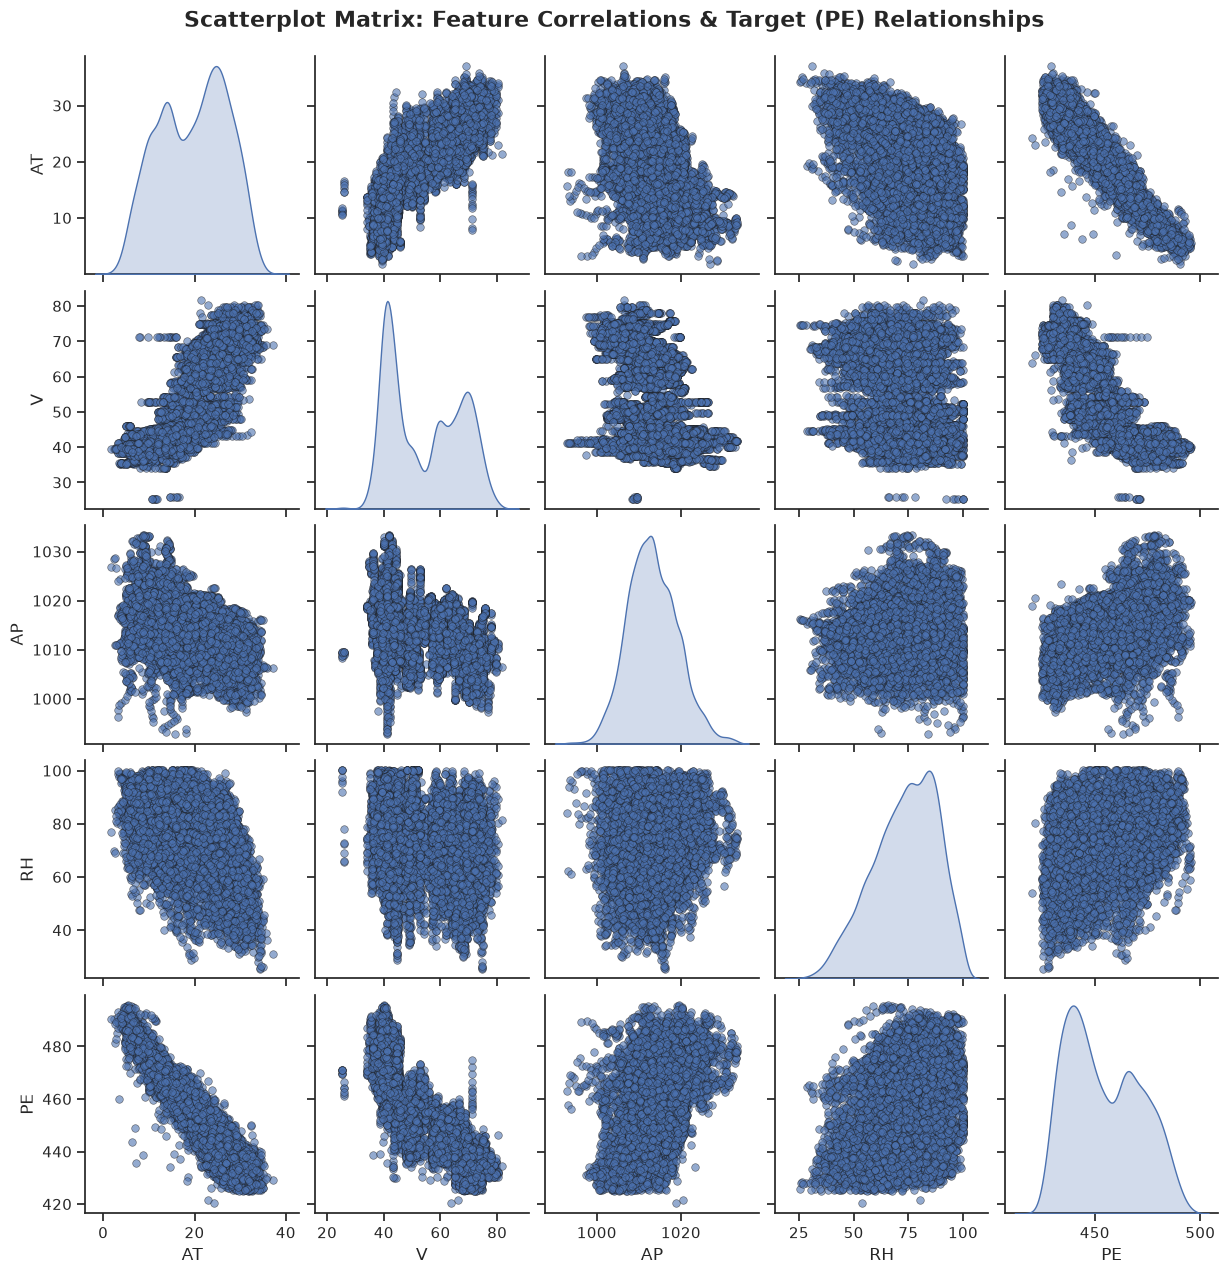

In [10]:
import seaborn as sns
import pandas as pd

# Convert polars DataFrame to pandas for seaborn plotting compatibility
pd_df = df.to_pandas()

# Generate a scatterplot matrix (pairplot) to show correlations among features and the target PE
sns.set_theme(style="ticks")
g = sns.pairplot(pd_df, diag_kind="kde", plot_kws={'alpha': 0.6, 's': 30, 'edgecolor': 'k'})
g.fig.suptitle("Scatterplot Matrix: Feature Correlations & Target (PE) Relationships", y=1.02, fontsize=16, fontweight='bold')
plt.show()

=== Trained Model Parameters (Cauchy Loss) ===
Intercept (Bias): 453.9270
Coefficient for AT: -15.5077
Coefficient for V: -3.1595
Coefficient for AP: 0.2214
Coefficient for RH: -2.2943
Final Training Cauchy Loss: 2.2727
Final Test Cauchy Loss: 2.2682

=== 95% Confidence Intervals ===
Intercept (Bias)    : 453.9270  |  SE: 0.0585  |  95% CI: [453.8123, 454.0417]
AT Coefficient      : -15.5077  |  SE: 0.1429  |  95% CI: [-15.7878, -15.2276]
V Coefficient       :  -3.1595  |  SE: 0.1159  |  95% CI: [ -3.3868,  -2.9323]
AP Coefficient      :   0.2214  |  SE: 0.0706  |  95% CI: [  0.0831,   0.3598]
RH Coefficient      :  -2.2943  |  SE: 0.0768  |  95% CI: [ -2.4447,  -2.1438]


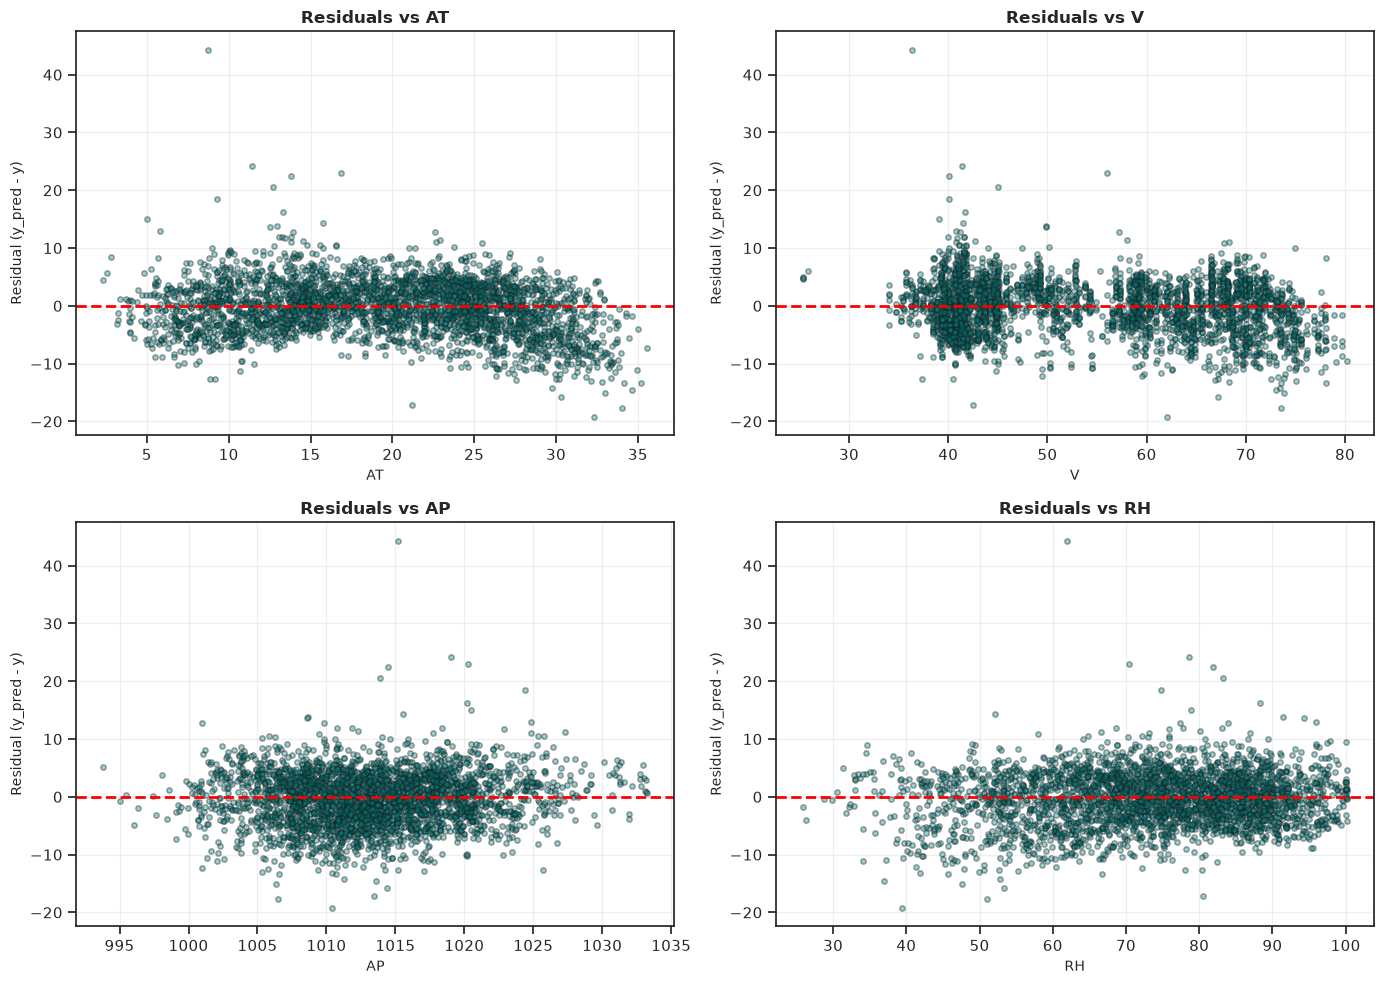

In [11]:
import numpy as np
import torch
from scipy import stats
import matplotlib.pyplot as plt


weights = model.weights.detach().cpu().numpy().flatten()
bias = model.bias.detach().cpu().numpy().item()

print("=== Trained Model Parameters (Cauchy Loss) ===")
print(f"Intercept (Bias): {bias:.4f}")
feature_names = ['AT', 'V', 'AP', 'RH']
for i, col in enumerate(feature_names):
    print(f"Coefficient for {col}: {weights[i]:.4f}")
print(f"Final Training Cauchy Loss: {loss.item():.4f}")
print(f"Final Test Cauchy Loss: {test_loss.item():.4f}\n")


N = len(X_train)
P = X_train.shape[1] + 1

X_design = np.hstack([np.ones((N, 1)), X_train])

with torch.no_grad():
    y_pred_train = model(X_train_tensor).cpu().numpy()

# Residuals: y_pred - y
residuals_train = y_pred_train - y_train.reshape(-1, 1)

# Estimate residual variance
residual_variance = np.sum(residuals_train ** 2) / (N - P)
cov_matrix = residual_variance * np.linalg.inv(X_design.T @ X_design)
standard_errors = np.sqrt(np.diagonal(cov_matrix))

t_val = stats.t.ppf(0.975, df=N-P)
all_params = np.insert(weights, 0, bias)
param_names = ['Intercept (Bias)', 'AT Coefficient', 'V Coefficient', 'AP Coefficient', 'RH Coefficient']

print("=== 95% Confidence Intervals ===")
for i, name in enumerate(param_names):
    se = standard_errors[i]
    val = all_params[i]
    ci_lower = val - t_val * se
    ci_upper = val + t_val * se
    print(f"{name:20}: {val:8.4f}  |  SE: {se:6.4f}  |  95% CI: [{ci_lower:8.4f}, {ci_upper:8.4f}]")


with torch.no_grad():
    y_test_pred_np = model(X_test_tensor).cpu().numpy()
residuals_test = y_test_pred_np - y_test.reshape(-1, 1)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(feature_names):
    # Using original unscaled test feature values for clarity on the X-axis
    x_val = scaler.inverse_transform(X_test)[:, i]

    axes[i].scatter(x_val, residuals_test, alpha=0.4, color='teal', edgecolor='k', s=15)
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=2)
    axes[i].set_title(f'Residuals vs {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Residual (y_pred - y)', fontsize=10)
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [12]:
# logistics regression
# question 6

!pip install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# fetch dataset
mushroom = fetch_ucirepo(id=73)

#mushroom = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data')

# data (as pandas dataframes)
X = mushroom.data.features
y = mushroom.data.targets

# Show the first few rows of the features dataframe
X.head()

'''
cap describes the cap of the mushroom
bruises note any physical damage
odor is smell of the mushroom
gill describes the gills on the underside of the cap
stalk describes the "stem" of the mushroom
veil describes something growing mushrooms have to protect it
rings are any rings on the mushroom
'''


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,x,s,n,t,p,f,c,n,k,e,...,s,w,w,p,w,o,p,k,s,u
1,x,s,y,t,a,f,c,b,k,e,...,s,w,w,p,w,o,p,n,n,g
2,b,s,w,t,l,f,c,b,n,e,...,s,w,w,p,w,o,p,n,n,m
3,x,y,w,t,p,f,c,n,n,e,...,s,w,w,p,w,o,p,k,s,u
4,x,s,g,f,n,f,w,b,k,t,...,s,w,w,p,w,o,e,n,a,g


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder


constant_cols = [col for col in X.columns if X[col].nunique() <= 1]
print(f"Dropping constant columns: {constant_cols}")
X_cleaned = X.drop(columns=constant_cols)


X_encoded = pd.get_dummies(X_cleaned, drop_first=True, dtype=int)


le_target = LabelEncoder()

y_encoded = le_target.fit_transform(y.values.ravel())


X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Print summary statistics
print(f"\nFeatures shape after One-Hot Encoding: {X_encoded.shape}")
print(f"Training instances: {X_train_lr.shape[0]}")
print(f"Testing instances: {X_test_lr.shape[0]}")
print("Target Class Mapping:", dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))

# Display prepared features
X_encoded.head()

Dropping constant columns: ['veil-type']

Features shape after One-Hot Encoding: (8124, 94)
Training instances: 6499
Testing instances: 1625
Target Class Mapping: {'e': np.int64(0), 'p': np.int64(1)}


,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_g,cap-surface_s,cap-surface_y,cap-color_c,cap-color_e,...,population_n,population_s,population_v,population_y,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,1,0,1,0,0,0,...,0,1,0,0,0,0,0,0,1,0
1,0,0,0,0,1,0,1,0,0,0,...,1,0,0,0,1,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,1,0,0,0
3,0,0,0,0,1,0,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
4,0,0,0,0,1,0,1,0,0,0,...,0,0,0,0,1,0,0,0,0,0


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Test Accuracy: 99.82%

Classification Report:
               precision    recall  f1-score   support

   Edible (0)       1.00      1.00      1.00       842
Poisonous (1)       1.00      1.00      1.00       783

     accuracy                           1.00      1625
    macro avg       1.00      1.00      1.00      1625
 weighted avg       1.00      1.00      1.00      1625



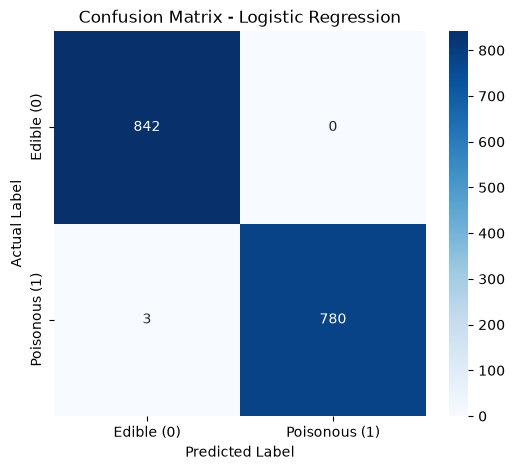

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt



lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_lr, y_train_lr)


y_pred_lr = lr_model.predict(X_test_lr)


accuracy = accuracy_score(y_test_lr, y_pred_lr)
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_lr, y_pred_lr, target_names=['Edible (0)', 'Poisonous (1)']))


cm = confusion_matrix(y_test_lr, y_pred_lr)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Edible (0)', 'Poisonous (1)'],
            yticklabels=['Edible (0)', 'Poisonous (1)'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


# im not sure if you wanted 5000 samples total
#this has ~8000 but only tested ~1500